In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

data_folder = Path(
    r"C:\Users\srinu\Desktop\sai vallepu"
)

inventory = pd.read_csv(
    data_folder / "perishable_inventory (1).csv"
)

batches = pd.read_csv(
    data_folder / "inventory_batches.csv"
)

products = pd.read_csv(
    data_folder / "products.csv"
)

discounts = pd.read_csv(
    data_folder / "discount_scenarios_simulated.csv"
)

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [2]:

datasets = {
    "Inventory": inventory,
    "Batches": batches,
    "Products": products,
    "Discounts": discounts
}

for name, df in datasets.items():
    print(f"\n===== {name} =====")

    print("Columns:", df.columns.tolist())

    sales_columns = [
        col for col in df.columns
        if any(word in col.lower()
               for word in [
                   "sales", "sold",
                   "demand", "units"
               ])
    ]

    date_columns = [
        col for col in df.columns
        if any(word in col.lower()
               for word in [
                   "date", "day", "time"
               ])
    ]

    print("Possible Sales Columns:", sales_columns)
    print("Possible Date Columns:", date_columns)



===== Inventory =====
Columns: ['product_id', 'date', 'category', 'opening_stock', 'units_received', 'units_sold', 'unit_price', 'discount_pct', 'days_to_expiry', 'temperature_c', 'waste_units', 'stockout_flag']
Possible Sales Columns: ['units_received', 'units_sold', 'waste_units']
Possible Date Columns: ['date', 'days_to_expiry']

===== Batches =====
Columns: ['batch_id', 'product_id', 'category', 'received_at', 'snapshot_date', 'expiry_date', 'initial_quantity', 'quantity_remaining', 'days_to_expiry', 'avg_daily_sales_7d', 'expected_demand_before_expiry', 'unit_price', 'unit_cost', 'discount_pct', 'expiry_risk_label', 'waste_units_actual_simulated']
Possible Sales Columns: ['avg_daily_sales_7d', 'expected_demand_before_expiry', 'waste_units_actual_simulated']
Possible Date Columns: ['snapshot_date', 'expiry_date', 'days_to_expiry']

===== Products =====
Columns: ['product_id', 'product_name', 'category', 'shelf_life_days', 'selling_price', 'unit_cost']
Possible Sales Columns: []
Po

In [3]:

for name, df in datasets.items():
    print(f"\n{name}")
    print("Total Rows:", len(df))
    print("Sample Data:")
    display(df.head(3))



Inventory
Total Rows: 1800
Sample Data:


,product_id,date,category,opening_stock,units_received,units_sold,unit_price,discount_pct,days_to_expiry,temperature_c,waste_units,stockout_flag
0,1001,2026-04-01,Dairy,27,0,6,32.0,0.0,1,4.1,0,0
1,1001,2026-04-02,Dairy,30,12,5,32.0,0.0,5,3.7,0,0
2,1001,2026-04-03,Dairy,38,0,14,32.0,0.0,2,4.6,0,0



Batches
Total Rows: 2000
Sample Data:


,batch_id,product_id,category,received_at,snapshot_date,expiry_date,initial_quantity,quantity_remaining,days_to_expiry,avg_daily_sales_7d,expected_demand_before_expiry,unit_price,unit_cost,discount_pct,expiry_risk_label,waste_units_actual_simulated
0,5001,1006,Produce,2026-08-14,2026-08-16,2026-08-21,140,72,5,23.38,117,45.0,28.0,5,1,64
1,5002,1006,Produce,2026-07-17,2026-07-23,2026-07-24,140,123,1,36.86,37,45.0,28.0,10,1,31
2,5003,1001,Dairy,2026-08-18,2026-08-20,2026-08-23,22,3,3,12.67,38,32.0,24.0,10,1,3



Products
Total Rows: 10
Sample Data:


,product_id,product_name,category,shelf_life_days,selling_price,unit_cost
0,1001,Milk 500ml,Dairy,5,32.0,24.0
1,1002,Yogurt Cup,Dairy,10,25.0,17.0
2,1003,Bread Loaf,Bakery,4,40.0,26.0



Discounts
Total Rows: 10000
Sample Data:


,batch_id,product_id,days_to_expiry,quantity_remaining,discount_pct,estimated_units_sold_simulated,estimated_revenue_simulated,estimated_gross_margin_simulated
0,5001,1006,5,72,0,72,3240.0,1224.0
1,5001,1006,5,72,5,72,3078.0,1062.0
2,5001,1006,5,72,10,72,2916.0,900.0


In [4]:

# Find possible sales datasets and columns

for name, df in datasets.items():
    print(f"\n===== {name} =====")
    print("Rows:", len(df))

    for col in df.columns:
        print(col, ":", df[col].dtype)

    print("\nFirst 5 Rows:")
    display(df.head())



===== Inventory =====
Rows: 1800
product_id : int64
date : str
category : str
opening_stock : int64
units_received : int64
units_sold : int64
unit_price : float64
discount_pct : float64
days_to_expiry : int64
temperature_c : float64
waste_units : int64
stockout_flag : int64

First 5 Rows:


,product_id,date,category,opening_stock,units_received,units_sold,unit_price,discount_pct,days_to_expiry,temperature_c,waste_units,stockout_flag
0,1001,2026-04-01,Dairy,27,0,6,32.0,0.0,1,4.1,0,0
1,1001,2026-04-02,Dairy,30,12,5,32.0,0.0,5,3.7,0,0
2,1001,2026-04-03,Dairy,38,0,14,32.0,0.0,2,4.6,0,0
3,1001,2026-04-04,Dairy,49,0,11,32.0,0.0,0,5.7,0,0
4,1001,2026-04-05,Dairy,19,13,12,32.0,0.0,0,3.0,0,0



===== Batches =====
Rows: 2000
batch_id : int64
product_id : int64
category : str
received_at : str
snapshot_date : str
expiry_date : str
initial_quantity : int64
quantity_remaining : int64
days_to_expiry : int64
avg_daily_sales_7d : float64
expected_demand_before_expiry : int64
unit_price : float64
unit_cost : float64
discount_pct : int64
expiry_risk_label : int64
waste_units_actual_simulated : int64

First 5 Rows:


,batch_id,product_id,category,received_at,snapshot_date,expiry_date,initial_quantity,quantity_remaining,days_to_expiry,avg_daily_sales_7d,expected_demand_before_expiry,unit_price,unit_cost,discount_pct,expiry_risk_label,waste_units_actual_simulated
0,5001,1006,Produce,2026-08-14,2026-08-16,2026-08-21,140,72,5,23.38,117,45.0,28.0,5,1,64
1,5002,1006,Produce,2026-07-17,2026-07-23,2026-07-24,140,123,1,36.86,37,45.0,28.0,10,1,31
2,5003,1001,Dairy,2026-08-18,2026-08-20,2026-08-23,22,3,3,12.67,38,32.0,24.0,10,1,3
3,5004,1003,Bakery,2026-08-21,2026-08-26,2026-08-25,141,141,-1,14.52,0,40.0,26.0,10,1,114
4,5005,1007,Produce,2026-07-16,2026-07-19,2026-07-30,139,52,11,13.09,144,120.0,78.0,20,1,34



===== Products =====
Rows: 10
product_id : int64
product_name : str
category : str
shelf_life_days : int64
selling_price : float64
unit_cost : float64

First 5 Rows:


,product_id,product_name,category,shelf_life_days,selling_price,unit_cost
0,1001,Milk 500ml,Dairy,5,32.0,24.0
1,1002,Yogurt Cup,Dairy,10,25.0,17.0
2,1003,Bread Loaf,Bakery,4,40.0,26.0
3,1004,Paneer 200g,Dairy,7,85.0,62.0
4,1005,Spinach Pack,Produce,3,30.0,18.0



===== Discounts =====
Rows: 10000
batch_id : int64
product_id : int64
days_to_expiry : int64
quantity_remaining : int64
discount_pct : int64
estimated_units_sold_simulated : int64
estimated_revenue_simulated : float64
estimated_gross_margin_simulated : float64

First 5 Rows:


,batch_id,product_id,days_to_expiry,quantity_remaining,discount_pct,estimated_units_sold_simulated,estimated_revenue_simulated,estimated_gross_margin_simulated
0,5001,1006,5,72,0,72,3240.0,1224.0
1,5001,1006,5,72,5,72,3078.0,1062.0
2,5001,1006,5,72,10,72,2916.0,900.0
3,5001,1006,5,72,15,72,2754.0,738.0
4,5001,1006,5,72,20,72,2592.0,576.0


In [5]:

for name, df in datasets.items():

    sales_cols = [
        col for col in df.columns
        if any(x in col.lower()
               for x in ["sales", "sold", "demand"])
    ]

    date_cols = [
        col for col in df.columns
        if any(x in col.lower()
               for x in ["date", "timestamp"])
    ]

    product_cols = [
        col for col in df.columns
        if "product" in col.lower()
        or "item" in col.lower()
    ]

    print(f"\n{name}")
    print("Sales:", sales_cols)
    print("Dates:", date_cols)
    print("Products:", product_cols)



Inventory
Sales: ['units_sold']
Dates: ['date']
Products: ['product_id']

Batches
Sales: ['avg_daily_sales_7d', 'expected_demand_before_expiry']
Dates: ['snapshot_date', 'expiry_date']
Products: ['product_id']

Products
Sales: []
Dates: []
Products: ['product_id', 'product_name']

Discounts
Sales: ['estimated_units_sold_simulated']
Dates: []
Products: ['product_id']


In [6]:

import pandas as pd
import numpy as np

# Select relevant columns
sales = inventory[
    ["date", "product_id", "units_sold"]
].copy()

# Convert date column
sales["date"] = pd.to_datetime(
    sales["date"], errors="coerce"
)

# Convert sales to numeric
sales["units_sold"] = pd.to_numeric(
    sales["units_sold"], errors="coerce"
)

# Remove invalid rows
sales = sales.dropna(
    subset=["date", "product_id", "units_sold"]
)

# Remove negative sales quantities
sales = sales[sales["units_sold"] >= 0]

# Combine sales for the same product and date
sales = sales.groupby(
    ["product_id", "date"], as_index=False
)["units_sold"].sum()

sales = sales.sort_values(
    ["product_id", "date"]
).reset_index(drop=True)

print("Sales data prepared successfully!")
display(sales.head())
print("Total Rows:", len(sales))


Sales data prepared successfully!


,product_id,date,units_sold
0,1001,2026-04-01,6
1,1001,2026-04-02,5
2,1001,2026-04-03,14
3,1001,2026-04-04,11
4,1001,2026-04-05,12


Total Rows: 1800


In [7]:

# Create time features
sales["day_of_week"] = sales["date"].dt.dayofweek
sales["month"] = sales["date"].dt.month
sales["day_of_month"] = sales["date"].dt.day

# Historical sales features per product
group = sales.groupby("product_id")["units_sold"]

sales["sales_lag_1"] = group.shift(1)
sales["sales_lag_7"] = group.shift(7)

sales["rolling_mean_7"] = (
    sales.groupby("product_id")["units_sold"]
    .transform(
        lambda x: x.shift(1).rolling(7).mean()
    )
)

# Remove rows without enough history
model_data = sales.dropna(
    subset=[
        "sales_lag_1",
        "sales_lag_7",
        "rolling_mean_7"
    ]
).copy()

print("Feature engineering completed!")
print("Training rows available:", len(model_data))
display(model_data.head())


Feature engineering completed!
Training rows available: 1730


,product_id,date,units_sold,day_of_week,month,day_of_month,sales_lag_1,sales_lag_7,rolling_mean_7
7,1001,2026-04-08,14,2,4,8,14.0,6.0,10.714286
8,1001,2026-04-09,8,3,4,9,14.0,5.0,11.857143
9,1001,2026-04-10,11,4,4,10,8.0,14.0,12.285714
10,1001,2026-04-11,16,5,4,11,11.0,11.0,11.857143
11,1001,2026-04-12,11,6,4,12,16.0,12.0,12.571429


In [8]:

from sklearn.model_selection import train_test_split

features = [
    "day_of_week",
    "month",
    "day_of_month",
    "sales_lag_1",
    "sales_lag_7",
    "rolling_mean_7"
]

# Sort chronologically
model_data = model_data.sort_values("date")

# Use latest 20% of distinct dates for testing
unique_dates = sorted(model_data["date"].unique())

if len(unique_dates) < 5:
    raise ValueError("Not enough dates for time-based testing.")

split_index = int(len(unique_dates) * 0.8)
cutoff_date = unique_dates[split_index]

train = model_data[
    model_data["date"] < cutoff_date
]

test = model_data[
    model_data["date"] >= cutoff_date
]

X_train = train[features]
y_train = train["units_sold"]

X_test = test[features]
y_test = test["units_sold"]

print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))


Training Rows: 1380
Testing Rows: 350


In [9]:

from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("WasteWise Demand Forecasting Model Trained!")


WasteWise Demand Forecasting Model Trained!


In [10]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

predictions = model.predict(X_test)
predictions = np.maximum(predictions, 0)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)
r2 = r2_score(y_test, predictions)

print("MODEL EVALUATION")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))


MODEL EVALUATION
MAE: 3.88
RMSE: 5.04
R2 Score: 0.707


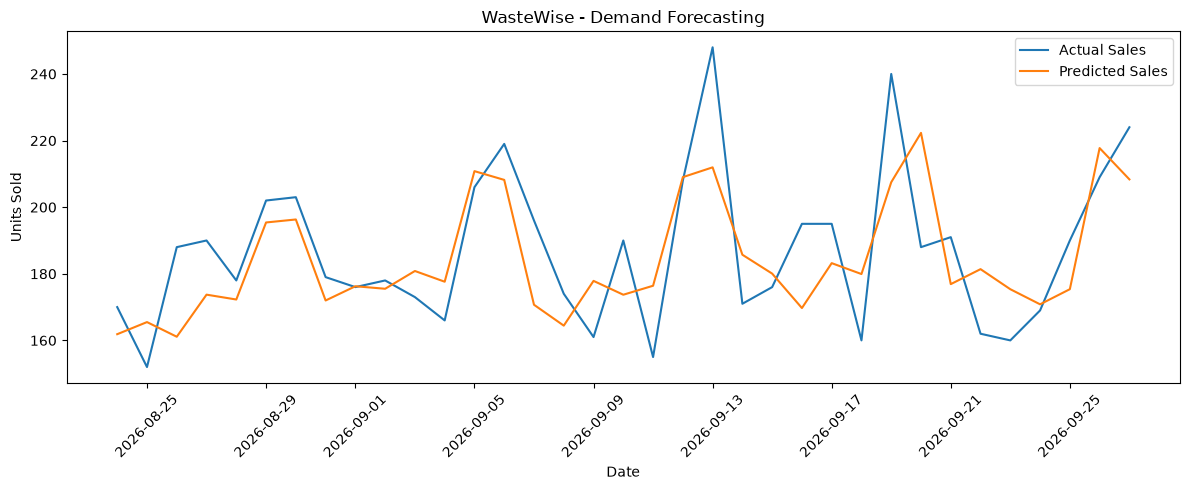

In [11]:

import matplotlib.pyplot as plt

results = test[["date", "product_id"]].copy()
results["Actual"] = y_test.values
results["Predicted"] = predictions

daily_results = results.groupby("date")[
    ["Actual", "Predicted"]
].sum()

plt.figure(figsize=(12, 5))

plt.plot(
    daily_results.index,
    daily_results["Actual"],
    label="Actual Sales"
)

plt.plot(
    daily_results.index,
    daily_results["Predicted"],
    label="Predicted Sales"
)

plt.title("WasteWise - Demand Forecasting")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [12]:

import joblib
from pathlib import Path

model_folder = (
    Path(r"C:\Users\srinu\Desktop\sai vallepu")
    / "WasteWise-AI" / "ml" / "artifacts"
)

model_folder.mkdir(
    parents=True,
    exist_ok=True
)

joblib.dump(
    {"model": model, "features": features},
    model_folder / "demand_forecast_model.pkl"
)

print("Demand Forecasting Model Saved Successfully!")


Demand Forecasting Model Saved Successfully!


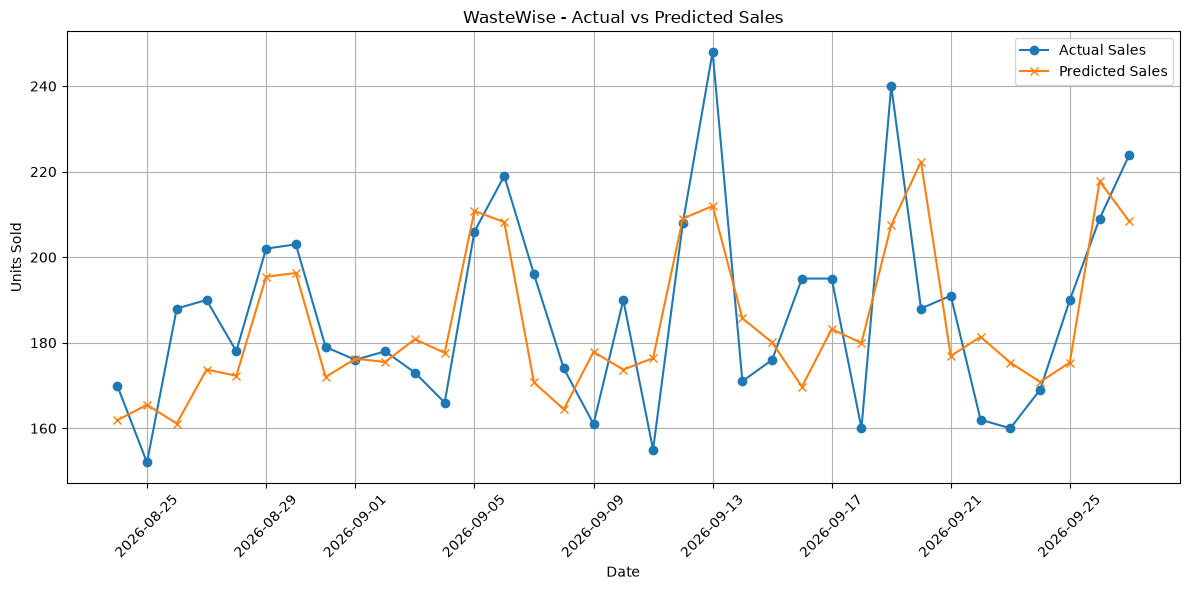

In [15]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Generate predictions
predictions = model.predict(X_test)
predictions = np.maximum(predictions, 0)

# Prepare results
results = test[["date", "product_id"]].copy()

results["Actual"] = y_test.to_numpy()
results["Predicted"] = predictions

# Aggregate sales by date
daily_results = results.groupby("date")[
    ["Actual", "Predicted"]
].sum()

# Create graph
plt.figure(figsize=(12, 6))

plt.plot(
    daily_results.index,
    daily_results["Actual"],
    label="Actual Sales",
    marker="o"
)

plt.plot(
    daily_results.index,
    daily_results["Predicted"],
    label="Predicted Sales",
    marker="x"
)

plt.title("WasteWise - Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


In [16]:

import joblib
from pathlib import Path

model_folder = Path(
    r"C:\Users\srinu\Desktop\sai vallepu\WasteWise-AI\ml\artifacts"
)

model_folder.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {"model": model, "features": features},
    model_folder / "demand_forecast_model.pkl"
)

print("Model saved successfully!")


Model saved successfully!
